In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values

print("Dataset Shape:", df.shape)
print("Target Distribution:")
print(pd.Series(y).value_counts())

Dataset Shape: (302, 14)
Target Distribution:
1    164
0    138
Name: count, dtype: int64


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 211
Validation Samples: 45
Testing Samples: 46


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

In [9]:
trained_models = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
SVM trained successfully


C:\Users\mahir\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [10]:
def calculate_metrics(actual, predicted):

    TP = np.sum((actual == 1) & (predicted == 1))
    TN = np.sum((actual == 0) & (predicted == 0))
    FP = np.sum((actual == 0) & (predicted == 1))
    FN = np.sum((actual == 1) & (predicted == 0))

    accuracy = (TP + TN) / len(actual)

    precision = TP / (TP + FP) if TP + FP > 0 else 0

    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [11]:
validation_scores = {}

for name, model in trained_models.items():

    predictions = model.predict(X_val_scaled)

    metrics = calculate_metrics(y_val, predictions)

    validation_scores[name] = metrics["F1 Score"]

    print(name, "Validation F1:", round(metrics["F1 Score"], 4))

total_score = sum(validation_scores.values())

if total_score > 0:
    model_weights = {
        name: score / total_score
        for name, score in validation_scores.items()
    }
else:
    model_weights = {
        name: 1 / len(trained_models)
        for name in trained_models
    }

print("\nDynamic Model Weights:")

for name, weight in model_weights.items():
    print(name, ":", round(weight, 4))

Logistic Regression Validation F1: 0.8519
Decision Tree Validation F1: 0.8235
Random Forest Validation F1: 0.8462
SVM Validation F1: 0.8302

Dynamic Model Weights:
Logistic Regression : 0.2542
Decision Tree : 0.2457
Random Forest : 0.2525
SVM : 0.2477


In [12]:
def manual_hard_voting(X_data):

    weighted_votes = np.zeros((len(X_data), 2))

    for name, model in trained_models.items():

        predictions = model.predict(X_data)
        weight = model_weights[name]

        for class_label in [0, 1]:
            weighted_votes[:, class_label] += (
                (predictions == class_label) * weight
            )

    final_predictions = np.argmax(weighted_votes, axis=1)

    return final_predictions


hard_predictions = manual_hard_voting(X_test_scaled)

print("Hard Voting Predictions:")
print(hard_predictions[:20])

Hard Voting Predictions:
[1 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0 0]


In [13]:
def manual_soft_voting(X_data):

    weighted_probabilities = np.zeros(len(X_data))

    for name, model in trained_models.items():

        probabilities = model.predict_proba(X_data)[:, 1]

        weight = model_weights[name]

        weighted_probabilities += probabilities * weight

    final_predictions = (
        weighted_probabilities >= 0.5
    ).astype(int)

    return final_predictions


soft_predictions = manual_soft_voting(X_test_scaled)

print("Soft Voting Predictions:")
print(soft_predictions[:20])

Soft Voting Predictions:
[1 1 1 0 0 0 0 0 1 0 1 1 0 1 1 0 1 1 0 0]


In [14]:
hard_metrics = calculate_metrics(y_test, hard_predictions)
soft_metrics = calculate_metrics(y_test, soft_predictions)

voting_results = pd.DataFrame([
    {"Model": "Manual Hard Voting", **hard_metrics},
    {"Model": "Manual Soft Voting", **soft_metrics}
])

display(voting_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Manual Hard Voting,0.7391,0.8421,0.64,0.7273
1,Manual Soft Voting,0.7391,0.8421,0.64,0.7273


In [15]:
comparison = []

for name, model in trained_models.items():

    predictions = model.predict(X_test_scaled)

    metrics = calculate_metrics(y_test, predictions)

    comparison.append({
        "Model": name,
        **metrics
    })

comparison.append({
    "Model": "Manual Hard Voting",
    **hard_metrics
})

comparison.append({
    "Model": "Manual Soft Voting",
    **soft_metrics
})

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7609,0.8500,0.68,0.7556
1,Decision Tree,0.6957,0.8235,0.56,0.6667
2,Random Forest,0.7174,0.8333,0.60,0.6977
3,SVM,0.7609,0.8500,0.68,0.7556
4,Manual Hard Voting,0.7391,0.8421,0.64,0.7273
5,Manual Soft Voting,0.7391,0.8421,0.64,0.7273


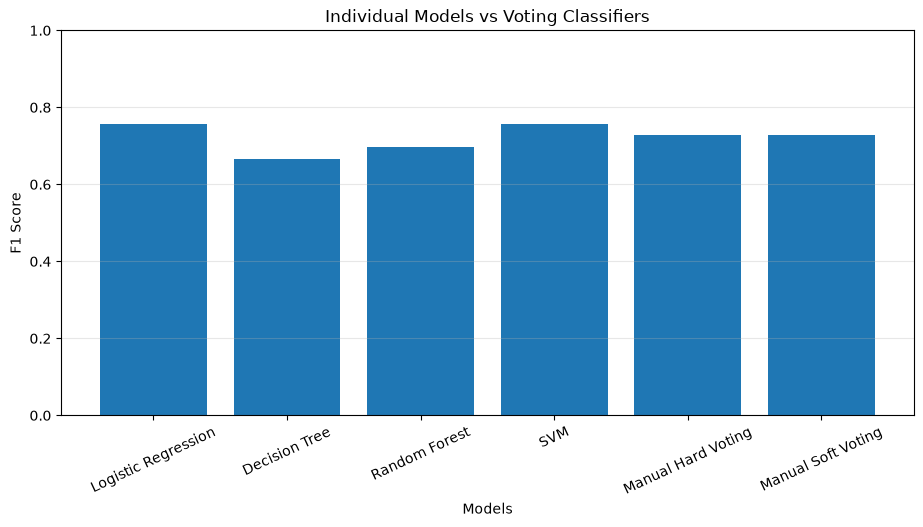

In [16]:
plt.figure(figsize=(11, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["F1 Score"]
)

plt.xlabel("Models")
plt.ylabel("F1 Score")
plt.title("Individual Models vs Voting Classifiers")

plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [17]:
best_voting = voting_results.loc[
    voting_results["F1 Score"].idxmax(), "Model"
]

print("Better Voting Method:", best_voting)

print("""
Conclusion:

Hard Voting combines predictions by selecting the class
with the highest weighted number of votes.

Soft Voting combines predicted probabilities using
weighted averages and then applies a classification threshold.

Dynamic weights are calculated using validation F1 scores.
Models with better validation F1 scores receive higher weights.

Voting classifiers combine multiple models and may improve
prediction performance, although improvement is not guaranteed.

The test dataset is used only for final evaluation.
""")

Better Voting Method: Manual Hard Voting

Conclusion:

Hard Voting combines predictions by selecting the class
with the highest weighted number of votes.

Soft Voting combines predicted probabilities using
weighted averages and then applies a classification threshold.

Dynamic weights are calculated using validation F1 scores.
Models with better validation F1 scores receive higher weights.

Voting classifiers combine multiple models and may improve
prediction performance, although improvement is not guaranteed.

The test dataset is used only for final evaluation.

